# 07 — Desbalanceo de Clases
## Pipeline CAD-TBX11K | Diagnóstico Asistido por Computador en Tuberculosis

El dataset TBX11K presenta un desbalanceo real: `health` y `sick` tienen 3800 imágenes
cada una, mientras que `tb` tiene solo 800 (proporción ≈ 4.75:1). Un modelo entrenado sin
corrección tiende a favorecer las clases mayoritarias, produciendo un recall bajo en `tb`
— precisamente la clase de mayor interés clínico.

### Familias de técnicas (según la guía de la asignatura)

Las estrategias para tratar el desbalanceo se agrupan en tres familias:

1. **Modificación de los datos** — cambian la distribución de clases: submuestreo,
   sobremuestreo y métodos sintéticos/híbridos (SMOTE, ADASYN, SMOTE+ENN, ...).
2. **Modificación del modelo** — no alteran los datos; ajustan el entrenamiento o la
   decisión: `class_weight='balanced'`, ajuste del umbral de decisión.
3. **Modificación de la evaluación** — usan métricas robustas al desbalance:
   recall, F1-macro, balanced accuracy, ROC-AUC y PR-AUC.

### Estrategias evaluadas en este notebook

Cada estrategia se entrena y evalúa **por separado**, como alternativas comparables.
No se combinan entre sí.

| Estrategia | Familia | Descripción | Altera los datos |
|---|---|---|---|
| Baseline | — | `LogisticRegression` sin corrección | No |
| `class_weight='balanced'` | Modelo | Pondera el costo de cada clase inversamente a su frecuencia | No |
| SMOTE | Datos | Genera muestras sintéticas de `tb` interpolando ejemplos reales (solo train) | Sí (solo train) |

> **¿Por qué NO se aplican juntas `class_weight` y SMOTE?**
> Pertenecen a **familias distintas** y persiguen el mismo objetivo por caminos distintos:
> SMOTE ya equilibra las clases re-muestreando, de modo que, tras SMOTE, los pesos de
> `class_weight='balanced'` quedan prácticamente neutros (≈1). Aplicar ambos es redundante
> (doble corrección) y dificulta atribuir la mejora a una causa. Por eso se comparan como
> alternativas y se elige UNA según las métricas.

### Regla fundamental

Cualquier técnica de balanceo se aplica **únicamente sobre el conjunto de entrenamiento**.
El conjunto de test permanece intacto con la distribución real del dataset para que la
evaluación refleje el desempeño en condiciones reales de operación.

### Flujo del notebook

```
X_train_selected.csv  y_train.csv     (del notebook 06)
X_test_selected.csv   y_test.csv      (del notebook 06, reservado)
         |
         v
 Verificacion del desbalanceo en train
         |
         v
 Baseline sin correccion (LogisticRegression)
         |
         +--> Estrategia 1 (familia modelo): class_weight='balanced'
         |
         +--> Estrategia 2 (familia datos):  SMOTE sobre train
         |
         v
 Comparativa: recall, F1-macro, balanced accuracy, ROC, PR
         |
         v
 Seleccion de la mejor estrategia
         |
         v
     Notebook 08
  Modelos ML
```


## 0. Configuración del entorno

In [1]:
# Se configura el path del proyecto y se importan las librerías necesarias.

import sys, os, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from pathlib import Path
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    balanced_accuracy_score,
    roc_curve, auc,
    precision_recall_curve, average_precision_score,
)

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.visualization import set_publication_style

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

CLASS_NAMES  = ['health', 'sick', 'tb']
PALETTE      = {'health': '#2166AC', 'sick': '#4DAC26', 'tb': '#D01C8B'}
COLORS       = [PALETTE[c] for c in CLASS_NAMES]

set_publication_style()
print('Entorno configurado correctamente.')

Entorno configurado correctamente.


## 1. Carga de los splits del notebook 06

In [2]:
# Se cargan los archivos generados por el notebook 06.
# No se realiza ningún split adicional: los conjuntos de train y test
# ya están definidos y son los únicos que se usarán en todo el pipeline.

DATA_DIR = Path('..') / 'data'

for f in ['X_train_selected.csv', 'X_test_selected.csv', 'y_train.csv', 'y_test.csv']:
    if not (DATA_DIR / f).exists():
        raise FileNotFoundError(
            f'No se encontró {f}. Ejecuta primero el notebook 06.'
        )

X_train = pd.read_csv(DATA_DIR / 'X_train_selected.csv').values
X_test  = pd.read_csv(DATA_DIR / 'X_test_selected.csv').values
y_train = pd.read_csv(DATA_DIR / 'y_train.csv')['label'].values
y_test  = pd.read_csv(DATA_DIR / 'y_test.csv')['label'].values

print(f'X_train : {X_train.shape}')
print(f'X_test  : {X_test.shape}  (reservado)')
print()
print('Distribución en train:')
unique, counts = np.unique(y_train, return_counts=True)
for cls, cnt in zip(unique, counts):
    print(f'  {CLASS_NAMES[cls]:6s} (label={cls}): {cnt} muestras')
print()
print('Distribución en test:')
unique, counts = np.unique(y_test, return_counts=True)
for cls, cnt in zip(unique, counts):
    print(f'  {CLASS_NAMES[cls]:6s} (label={cls}): {cnt} muestras')

X_train : (6720, 2000)
X_test  : (1680, 2000)  (reservado)

Distribución en train:
  health (label=0): 3040 muestras
  sick   (label=1): 3040 muestras
  tb     (label=2): 640 muestras

Distribución en test:
  health (label=0): 760 muestras
  sick   (label=1): 760 muestras
  tb     (label=2): 160 muestras


## 2. El problema: desbalanceo en train

Ratio de desbalanceo en train:
  health: 3040 muestras  (4.8x respecto a tb)
  sick  : 3040 muestras  (4.8x respecto a tb)
  tb    : 640 muestras  (1.0x respecto a tb)


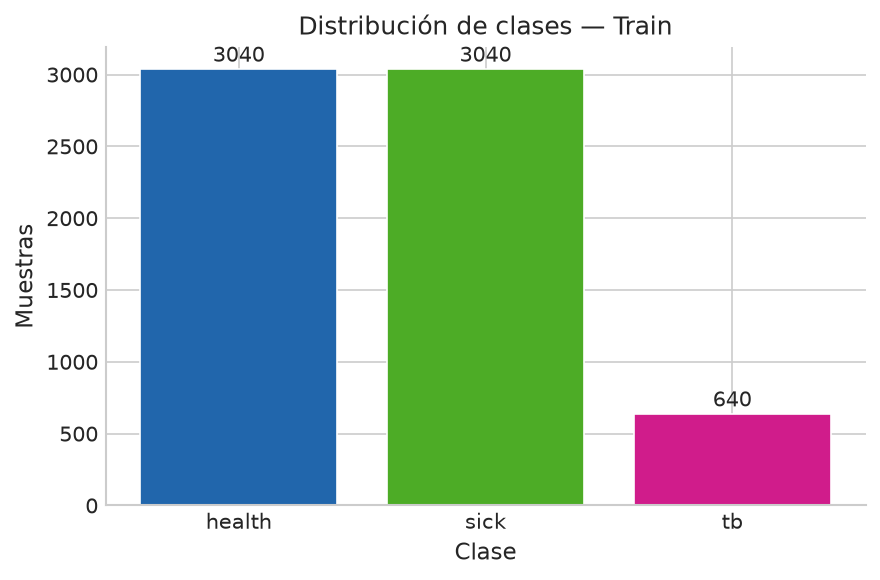

In [3]:
# Se visualiza la distribución de clases en el conjunto de entrenamiento.
# El desbalanceo real del dataset (proporcional al 80 % de las 8400 imágenes)
# se refleja directamente en el train.

unique_train, counts_train = np.unique(y_train, return_counts=True)
n_max = counts_train.max()
n_tb  = counts_train[unique_train == 2][0]

print('Ratio de desbalanceo en train:')
for cls, cnt in zip(unique_train, counts_train):
    ratio = cnt / n_tb
    print(f'  {CLASS_NAMES[cls]:6s}: {cnt} muestras  ({ratio:.1f}x respecto a tb)')

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(
    [CLASS_NAMES[c] for c in unique_train],
    counts_train,
    color=[PALETTE[CLASS_NAMES[c]] for c in unique_train],
    edgecolor='white',
    linewidth=0.8,
)
for bar, cnt in zip(bars, counts_train):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 15,
        str(cnt),
        ha='center', va='bottom', fontsize=10,
    )
ax.set_title('Distribución de clases — Train', fontsize=12)
ax.set_ylabel('Muestras', fontsize=11)
ax.set_xlabel('Clase', fontsize=11)
fig.tight_layout()
# fig.savefig('../reports/07_distribucion_train.png', dpi=300, bbox_inches='tight')  # uncomment to save
plt.show()

## 3. Normalización

In [4]:
# El StandardScaler se ajusta únicamente sobre el train.
# El test se transforma con los parámetros del train para evitar data leakage.
# SMOTE se aplicará después sobre los datos ya normalizados.

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print('Normalización completada.')
print(f'  Media train (primeras 3 features): {X_train_sc[:, :3].mean(axis=0).round(4)}')
print(f'  Std  train (primeras 3 features): {X_train_sc[:, :3].std(axis=0).round(4)}')

Normalización completada.
  Media train (primeras 3 features): [ 0.  0. -0.]
  Std  train (primeras 3 features): [1. 1. 1.]


## 4. Baseline — sin corrección del desbalanceo

In [5]:
# Se entrena una Logistic Regression sin ninguna corrección.
# El objetivo es cuantificar el efecto del desbalanceo sobre el recall de tb.
# Un modelo que ignora el desbalanceo aprende a predecir principalmente
# las clases mayoritarias porque minimizar el error global no requiere
# detectar bien la clase minoritaria.

lr_base = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr_base.fit(X_train_sc, y_train)
y_pred_base = lr_base.predict(X_test_sc)

print('=== Baseline (sin corrección) ===')
print(classification_report(y_test, y_pred_base, target_names=CLASS_NAMES))
print(f'Balanced accuracy: {balanced_accuracy_score(y_test, y_pred_base):.4f}')

=== Baseline (sin corrección) ===
              precision    recall  f1-score   support

      health       0.98      0.98      0.98       760
        sick       0.98      0.98      0.98       760
          tb       0.88      0.87      0.87       160

    accuracy                           0.97      1680
   macro avg       0.94      0.94      0.94      1680
weighted avg       0.97      0.97      0.97      1680

Balanced accuracy: 0.9418


## 5. Estrategia 1 — class_weight='balanced'

In [6]:
# class_weight='balanced' asigna a cada clase un peso inversamente proporcional
# a su frecuencia: w_j = n_muestras / (n_clases * n_j).
# Esto penaliza más los errores en la clase minoritaria durante el entrenamiento,
# sin modificar los datos de entrada.

# Nota: class_weight no altera los datos; entrena sobre el mismo train sin balancear.
lr_cw = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, class_weight='balanced')
lr_cw.fit(X_train_sc, y_train)
y_pred_cw = lr_cw.predict(X_test_sc)

print('=== Estrategia 1: class_weight=balanced ===')
print(classification_report(y_test, y_pred_cw, target_names=CLASS_NAMES))
print(f'Balanced accuracy: {balanced_accuracy_score(y_test, y_pred_cw):.4f}')

=== Estrategia 1: class_weight=balanced ===
              precision    recall  f1-score   support

      health       0.98      0.98      0.98       760
        sick       0.98      0.97      0.98       760
          tb       0.87      0.88      0.88       160

    accuracy                           0.97      1680
   macro avg       0.94      0.95      0.94      1680
weighted avg       0.97      0.97      0.97      1680

Balanced accuracy: 0.9451


## 6. Estrategia 2 — SMOTE

In [7]:
# SMOTE (Synthetic Minority Over-sampling Technique) genera muestras sintéticas
# de las clases minoritarias interpolando entre ejemplos reales:
#
#   muestra_nueva = ejemplo + lambda * (vecino_k - ejemplo)
#
# donde lambda se muestrea uniformemente en [0, 1].
#
# SMOTE se aplica ÚNICAMENTE sobre el conjunto de entrenamiento.
# El test permanece con la distribución real del dataset.

smote = SMOTE(random_state=RANDOM_STATE)
X_train_sm, y_train_sm = smote.fit_resample(X_train_sc, y_train)

print('Distribución después de SMOTE:')
unique_sm, counts_sm = np.unique(y_train_sm, return_counts=True)
for cls, cnt in zip(unique_sm, counts_sm):
    print(f'  {CLASS_NAMES[cls]:6s}: {cnt} muestras')

# El clasificador se deja neutro (sin class_weight) para aislar el efecto de SMOTE.
lr_sm = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr_sm.fit(X_train_sm, y_train_sm)
y_pred_sm = lr_sm.predict(X_test_sc)

print()
print('=== Estrategia 2: SMOTE ===')
print(classification_report(y_test, y_pred_sm, target_names=CLASS_NAMES))
print(f'Balanced accuracy: {balanced_accuracy_score(y_test, y_pred_sm):.4f}')

Distribución después de SMOTE:
  health: 3040 muestras
  sick  : 3040 muestras
  tb    : 3040 muestras

=== Estrategia 2: SMOTE ===
              precision    recall  f1-score   support

      health       0.98      0.98      0.98       760
        sick       0.98      0.97      0.98       760
          tb       0.87      0.88      0.87       160

    accuracy                           0.97      1680
   macro avg       0.94      0.94      0.94      1680
weighted avg       0.97      0.97      0.97      1680

Balanced accuracy: 0.9430


## 7. Comparativa de las tres estrategias

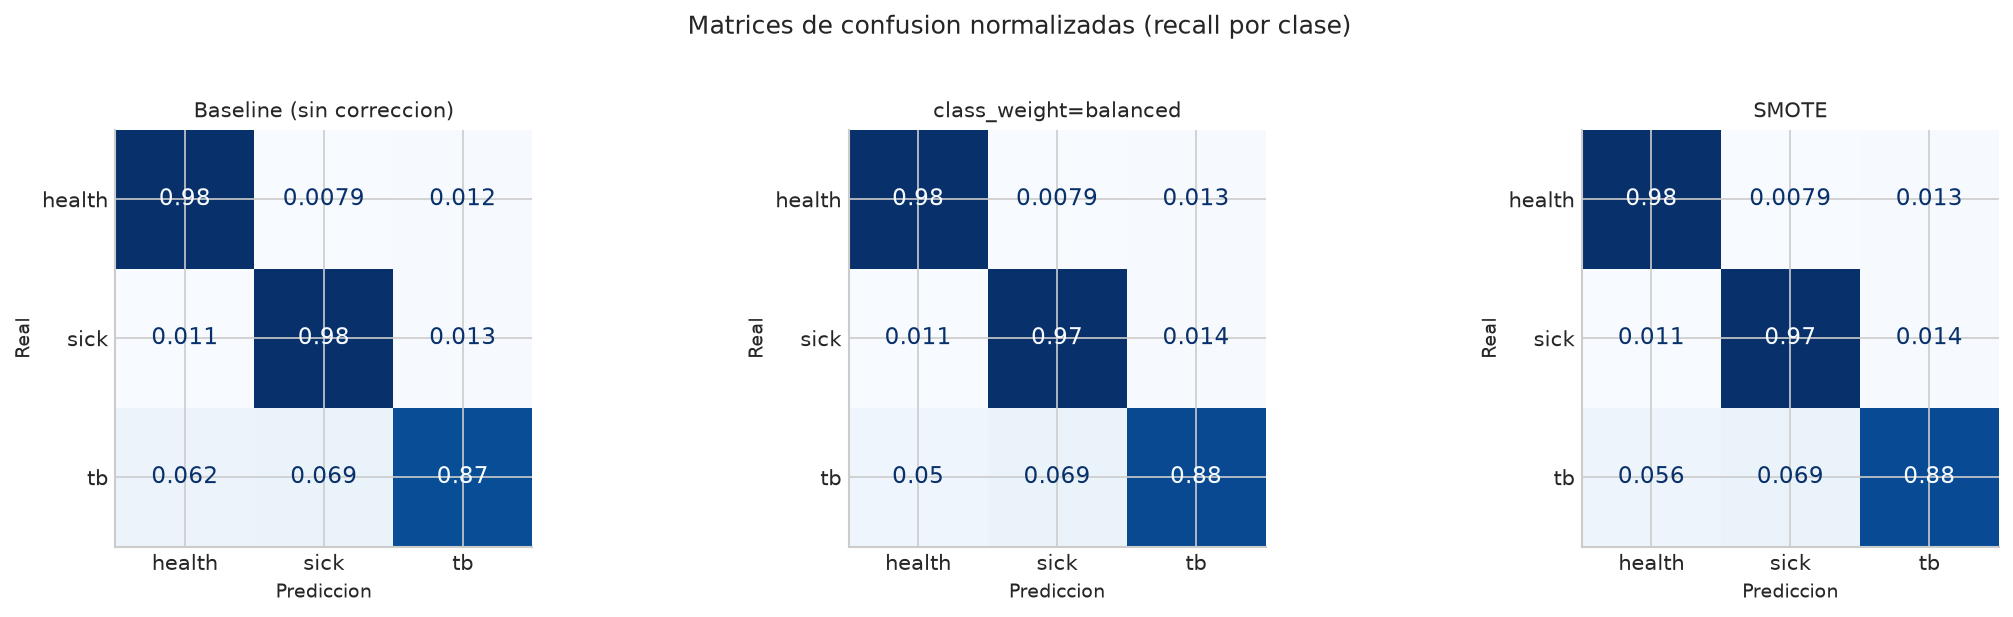

In [8]:
# Se comparan las tres estrategias mediante matrices de confusión normalizadas.
# La normalización por fila (normalize='true') muestra el recall de cada clase,
# lo que hace directamente visible el efecto del desbalanceo y su corrección.

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

configs = [
    (y_pred_base, 'Baseline (sin correccion)',   axes[0]),
    (y_pred_cw,   'class_weight=balanced',        axes[1]),
    (y_pred_sm,   'SMOTE',                        axes[2]),
]

for y_pred, titulo, ax in configs:
    disp = ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        display_labels=CLASS_NAMES,
        normalize='true',
        ax=ax,
        colorbar=False,
        cmap='Blues',
    )
    ax.set_title(titulo, fontsize=10)
    ax.set_xlabel('Prediccion', fontsize=9)
    ax.set_ylabel('Real', fontsize=9)

fig.suptitle('Matrices de confusion normalizadas (recall por clase)', fontsize=12, y=1.02)
fig.tight_layout()
# fig.savefig('../reports/07_confusion_matrices.png', dpi=300, bbox_inches='tight')  # uncomment to save
plt.show()

In [9]:
# Tabla resumen de métricas clave por estrategia.
# El recall de tb y la balanced accuracy son las métricas más informativas
# en presencia de desbalanceo: el accuracy global puede ser alto incluso
# cuando el modelo ignora la clase minoritaria.

from sklearn.metrics import recall_score, f1_score, accuracy_score

estrategias = {
    'Baseline': y_pred_base,
    'class_weight': y_pred_cw,
    'SMOTE': y_pred_sm,
}

print(f'{"Estrategia":<18}  {"Acc global":<12}  {"Balanced Acc":<14}  {"Recall tb":<11}  {"F1-macro"}')
print('-' * 72)
for nombre, y_pred in estrategias.items():
    acc  = accuracy_score(y_test, y_pred)
    bacc = balanced_accuracy_score(y_test, y_pred)
    rec_tb = recall_score(y_test, y_pred, labels=[2], average=None)[0]
    f1m  = f1_score(y_test, y_pred, average='macro')
    print(f'{nombre:<18}  {acc:<12.4f}  {bacc:<14.4f}  {rec_tb:<11.4f}  {f1m:.4f}')

best_strategy = max(
    estrategias,
    key=lambda nombre: balanced_accuracy_score(y_test, estrategias[nombre]),
)
print()
print(f'-> Mejor estrategia por balanced accuracy: {best_strategy}')


Estrategia          Acc global    Balanced Acc    Recall tb    F1-macro
------------------------------------------------------------------------
Baseline            0.9679        0.9418          0.8688       0.9432
class_weight        0.9679        0.9451          0.8812       0.9437
SMOTE               0.9673        0.9430          0.8750       0.9423

-> Mejor estrategia por balanced accuracy: class_weight


## 8. Curvas ROC y Precision-Recall

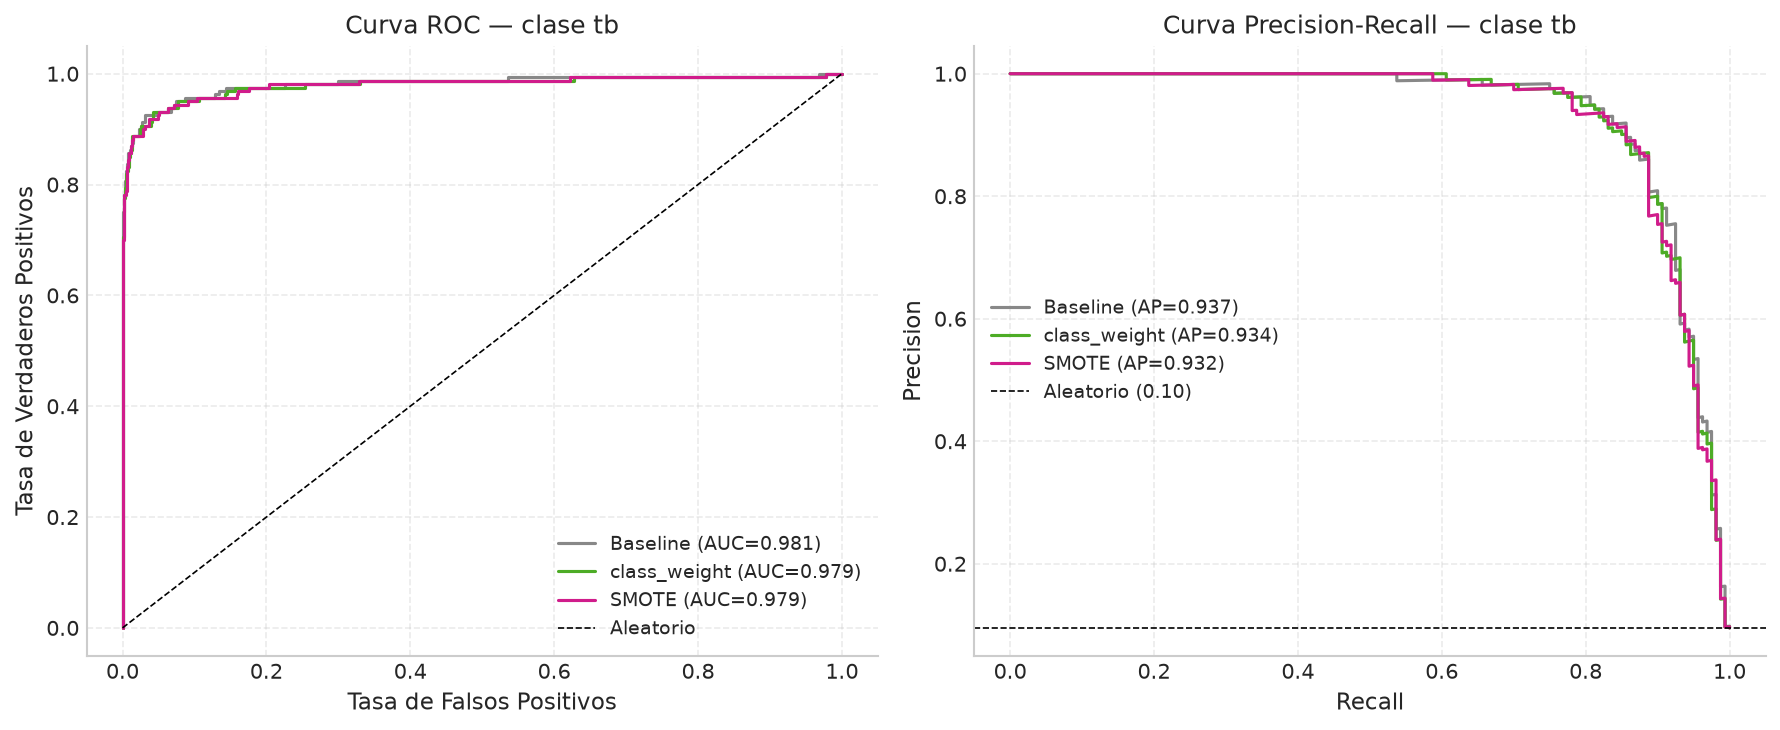

In [10]:
# Se generan curvas ROC y Precision-Recall para la clase tb en cada estrategia.
# Estas curvas son más informativas que el accuracy cuando hay desbalanceo:
# - ROC-AUC mide la capacidad de separación independientemente del umbral.
# - PR-AUC mide la precisión alcanzada a cada nivel de recall, siendo
#   especialmente relevante cuando la clase positiva es minoritaria.

y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

modelos = {
    'Baseline':     (lr_base, '#888888'),
    'class_weight': (lr_cw,   '#4DAC26'),
    'SMOTE':        (lr_sm,   '#D01C8B'),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for nombre, (modelo, color) in modelos.items():
    y_score = modelo.predict_proba(X_test_sc)

    # ROC — clase tb (índice 2)
    fpr, tpr, _ = roc_curve(y_test_bin[:, 2], y_score[:, 2])
    roc_auc = auc(fpr, tpr)
    axes[0].plot(fpr, tpr, color=color, lw=1.5, label=f'{nombre} (AUC={roc_auc:.3f})')

    # Precision-Recall — clase tb (índice 2)
    prec, rec, _ = precision_recall_curve(y_test_bin[:, 2], y_score[:, 2])
    pr_auc = average_precision_score(y_test_bin[:, 2], y_score[:, 2])
    axes[1].plot(rec, prec, color=color, lw=1.5, label=f'{nombre} (AP={pr_auc:.3f})')

# Línea de referencia ROC
axes[0].plot([0, 1], [0, 1], 'k--', lw=0.8, label='Aleatorio')
axes[0].set_xlabel('Tasa de Falsos Positivos', fontsize=11)
axes[0].set_ylabel('Tasa de Verdaderos Positivos', fontsize=11)
axes[0].set_title('Curva ROC — clase tb', fontsize=12)
axes[0].legend(fontsize=9)
axes[0].grid(True, linestyle='--', alpha=0.4)

# Línea de referencia PR (proporción real de tb en test)
prop_tb = (y_test == 2).mean()
axes[1].axhline(prop_tb, color='k', linestyle='--', lw=0.8, label=f'Aleatorio ({prop_tb:.2f})')
axes[1].set_xlabel('Recall', fontsize=11)
axes[1].set_ylabel('Precision', fontsize=11)
axes[1].set_title('Curva Precision-Recall — clase tb', fontsize=12)
axes[1].legend(fontsize=9)
axes[1].grid(True, linestyle='--', alpha=0.4)

fig.tight_layout()
# fig.savefig('../reports/07_curvas_roc_pr.png', dpi=300, bbox_inches='tight')  # uncomment to save
plt.show()

## Conclusiones

Cada estrategia se evaluó de forma independiente sobre el mismo conjunto de test reservado,
respetando la regla de aplicar cualquier balanceo solo sobre el train:

- **Baseline**: entrena sin corrección; referencia del efecto del desbalanceo.
- **class_weight='balanced'** (familia modelo): no altera los datos; repondera el costo.
- **SMOTE** (familia datos): genera ejemplos sintéticos de `tb` en el train.

Al comparar con balanced accuracy, recall de `tb`, F1-macro y las curvas ROC/PR se identifica
la estrategia que mejor equilibra la detección de las tres clases; ese resultado es el que se
traslada al notebook 08.

Nota: `class_weight` y SMOTE son enfoques **alternativos** (familias distintas), no
acumulables; aplicarlos juntos sería una doble corrección redundante.


**Siguiente etapa:** `08_Modelos_ML.ipynb`